# BIOT 6900 · Module 8 Assignment — Single-Cell & Spatial Omics
## Starter notebook: one tumor, two views

This is your **starter**. The plumbing is done for you: the two datasets load in one line each, and the tricky steps (whole-donor sampling, scVI setup, Harmony, the spatial graph) are already written. Your job is to fill in the cells marked **`# TODO`** and to answer the **TODO** questions in the markdown.

- **Part 1 (single-cell):** which cell types express your target?
- **Part 2 (spatial):** where do those cells and that target sit in the tumor?
- **Part 3:** connect the two in your report.

How to use it: run top to bottom, completing each TODO as you reach it. The provided cells must run first for the TODO cells to work. When you are done, **Kernel → Restart & Run All** so the whole notebook executes cleanly, then commit it with your report.

> **Compute:** Part 1's scVI step wants a GPU. Run on Explorer via Open OnDemand (JupyterLab on `courses-gpu`, 1 GPU). Part 2 is CPU-only. See the lab guides for the steps.

### Requirements
Environment: the course `biot6900` / Explorer environment (`scanpy`, `cellxgene-census`, `scvi-tools`, `harmonypy`, `squidpy`). Needs **Python 3.13 or earlier**. If an import fails, run the install cell once and restart the kernel.

In [ ]:
# Run once only if an import below fails, then restart the kernel. Python <= 3.13.
#!pip install "cellxgene-census" "scvi-tools" harmonypy squidpy scanpy leidenalg igraph

In [18]:
import os, sys
sys.dont_write_bytecode = True
os.environ["MPLCONFIGDIR"] = "/tmp/dineshkumar.de-mpl"
os.environ["NUMBA_CACHE_DIR"] = "/tmp/dineshkumar.de-numba"
os.environ["CUDA_VISIBLE_DEVICES"] = ""   # P100 not supported by this PyTorch; force CPU
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, facecolor="white")
try:
    import torch
    GPU = torch.cuda.is_available()
    print("GPU available:", GPU)
except Exception:
    GPU = False
    print("running on CPU")
print("scanpy", sc.__version__, "| squidpy", sq.__version__)

GPU available: False
scanpy 1.12.6 | squidpy 1.8.4


In [19]:
# Figure folder + helper so every report figure is saved automatically to ./figures
import os, json, warnings
os.makedirs("figures", exist_ok=True)
warnings.filterwarnings("ignore", category=FutureWarning)

def savefig(name):
    """Save the current figure to figures/<name>.png (200 dpi) and display it."""
    plt.gcf().savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

RESULTS = {}   # collects key numbers for the README / report (written out at the end)

---
# PART 1 · Single-cell: which cells express the target

## 1.1 · Pull the breast-cancer data  *(provided)*
This pulls breast-cancer blood/tumor cells from the CZ CELLxGENE Census and samples **10 whole donors**. You do not change anything here.

If the query returns zero cells on your Census version, replace the disease string with the exact one posted on Canvas (Census labels are version-specific).

In [20]:
import cellxgene_census

s3_cfg = {"vfs.s3.connect_timeout_ms": "60000",
          "vfs.s3.request_timeout_ms": "600000",
          "vfs.s3.connect_max_tries": "10",
          "vfs.s3.proxy_scheme": "http",
          "vfs.s3.proxy_host": "10.99.0.130",   # Explorer's proxy (from https_proxy)
          "vfs.s3.proxy_port": "3128"}
census = cellxgene_census.open_soma(census_version="2025-11-08", tiledb_config=s3_cfg)
obs = cellxgene_census.get_obs(
    census, "Homo sapiens",
    value_filter="disease == 'breast cancer' and is_primary_data == True",
    column_names=["soma_joinid", "donor_id", "assay", "cell_type"],
)
print(f"matching cells in the Census: {len(obs):,}")

# Sample whole donors (not scattered cells), so batch-aware steps have enough per donor.
rng = np.random.default_rng(0)
cells_per_donor = 2000
donor_sizes = obs["donor_id"].value_counts()
big_donors = donor_sizes[donor_sizes >= cells_per_donor].index.to_numpy()
donors = rng.choice(big_donors, size=min(10, len(big_donors)), replace=False)
sel = np.concatenate([
    rng.choice(obs.loc[obs["donor_id"] == d, "soma_joinid"].to_numpy(), size=cells_per_donor, replace=False)
    for d in donors
])
adata = cellxgene_census.get_anndata(
    census, "Homo sapiens", obs_coords=np.sort(sel),
    obs_column_names=["donor_id", "assay", "cell_type", "disease", "sex"],
    var_column_names=["feature_id", "feature_name"],
)
census.close()
adata.var_names = adata.var["feature_name"].astype(str)
adata.var_names_make_unique()

def broad_type(ct):
    ct = str(ct).lower()
    if "cd4" in ct or "cd8" in ct or "t cell" in ct or "thymocyte" in ct: return "T"
    if "plasma" in ct or "b cell" in ct: return "B"
    if "natural killer" in ct or "innate lymphoid" in ct: return "NK"
    if "monocyte" in ct: return "Monocyte"
    if "dendritic" in ct: return "DC"
    if "macrophage" in ct: return "Macrophage"
    if "epithel" in ct or "luminal" in ct or "basal" in ct or "carcinoma" in ct or "tumor" in ct: return "Epithelial/Tumor"
    if "fibroblast" in ct or "stromal" in ct: return "Fibroblast"
    if "endothel" in ct: return "Endothelial"
    return "Other"
adata.obs["cell_type_broad"] = adata.obs["cell_type"].map(broad_type).astype("category")
print(f"\n{adata.n_obs:,} cells from {len(donors)} donors")
print(adata.obs["cell_type_broad"].value_counts())

matching cells in the Census: 1,101,430


/shared/EL9/explorer/anaconda3/2024.06/lib/python3.12/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/shared/EL9/explorer/anaconda3/2024.06/lib/python3.12/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)



20,000 cells from 10 donors
cell_type_broad
T                   12121
Other                3125
Endothelial          1466
Macrophage           1260
Fibroblast           1118
B                     586
Epithelial/Tumor      152
Monocyte               73
NK                     61
DC                     38
Name: count, dtype: int64


/tmp/ipykernel_180882/745498535.py:34: UserWarning: Suffix used (-[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`. Example key collisions generated by the make_index_unique algorithm: ['SNORD115-1', 'SNORD115-2', 'SNORD115-3', 'SNORD115-4', 'SNORD115-5']
  adata.var_names_make_unique()


### 1.1b · Report cells, donors, assays (and check which target is supported)

In [21]:
n_donors = adata.obs["donor_id"].nunique()
print(f"cells: {adata.n_obs:,} | donors: {n_donors}")
print("\nassays:\n", adata.obs["assay"].value_counts().to_string())
print("\ncells per donor x broad type:")
display(pd.crosstab(adata.obs["donor_id"], adata.obs["cell_type_broad"]))
print("\nmost common fine cell types (what's inside 'Other'):")
print(adata.obs["cell_type"].value_counts().head(20).to_string())

n_epi = int((adata.obs["cell_type_broad"] == "Epithelial/Tumor").sum())
print(f"\nEpithelial/Tumor cells: {n_epi}")
print("-> ERBB2 is well supported" if n_epi >= 300 else
      "-> few epithelial cells: consider TARGET = 'CD68' (macrophage) in section 1.8")

RESULTS["single_cell"] = {"cells_loaded": int(adata.n_obs), "donors": int(n_donors),
                          "assays": adata.obs["assay"].value_counts().to_dict(),
                          "epithelial_cells": n_epi}

cells: 20,000 | donors: 10

assays:
 assay
10x 3' v3                                          13922
10x 3' v2                                           4078
10x 5' v2                                           2000
10x 3' v1                                              0
10x 3' transcription profiling                         0
10x 5' transcription profiling                         0
10x 5' v1                                              0
10x gene expression flex                               0
10x multiome                                           0
Asteria scRNA-seq kit                                  0
BD Rhapsody Targeted mRNA                              0
BD Rhapsody Whole Transcriptome Analysis               0
CEL-seq                                                0
CEL-seq2                                               0
Drop-seq                                               0
GEXSCOPE technology                                    0
HIVE CLX Single-Cell RNAseq Solution         

cell_type_broad,B,DC,Endothelial,Epithelial/Tumor,Fibroblast,Macrophage,Monocyte,NK,Other,T
donor_id,,,,,,,,,,
HTAPP-211,0,0,242,0,34,378,0,0,869,477
HTAPP-313,38,0,85,0,48,146,73,0,10,1600
HTAPP-516,0,0,351,0,234,220,0,0,212,983
HTAPP-806,0,0,238,0,148,53,0,0,33,1528
HTAPP-889,15,0,165,0,7,89,0,0,1363,361
HTAPP-997,0,0,145,0,92,63,0,0,519,1181
QianBRCA_BC_5,219,0,196,152,403,0,0,0,58,972
pal_Patient 0056,0,0,3,0,4,8,0,0,0,1985
pal_Patient 0176,313,36,31,0,77,65,0,61,61,1356



most common fine cell types (what's inside 'Other'):
cell_type
malignant cell                                                              9616
hepatocyte                                                                  2606
T cell                                                                      1713
macrophage                                                                  1250
fibroblast                                                                  1118
blood vessel endothelial cell                                                778
endothelial cell of hepatic sinusoid                                         345
endothelial cell                                                             313
memory B cell                                                                249
B cell                                                                       223
naive T cell                                                                 215
effector memory CD8-positive, alpha-beta T ce

In [22]:
# FIX: the starter's keyword mapping matched "t cell" inside "malignant cell",
# "myofibroblast cell" and "mast cell", mislabelling them as T cells.
fix = {"malignant cell": "Epithelial/Tumor", "myofibroblast cell": "Fibroblast", "mast cell": "Other"}
ct = adata.obs["cell_type"].astype(str)
broad = adata.obs["cell_type_broad"].astype(str).copy()
for fine, correct in fix.items():
    broad.loc[ct == fine] = correct
adata.obs["cell_type_broad"] = pd.Categorical(broad)
adata.uns.pop("cell_type_broad_colors", None)       # reset plot colours

print(adata.obs["cell_type_broad"].value_counts().to_string())
RESULTS["single_cell"]["label_fix"] = "malignant/myofibroblast/mast cells reassigned from T"
RESULTS["single_cell"]["epithelial_cells"] = int((adata.obs["cell_type_broad"] == "Epithelial/Tumor").sum())

cell_type_broad
Epithelial/Tumor    9768
Other               3142
T                   2462
Endothelial         1466
Macrophage          1260
Fibroblast          1144
B                    586
Monocyte              73
NK                    61
DC                    38


> **Note on the 1.1b output above:** the "few epithelial cells, consider CD68" message was printed *before* the label fix. After correcting the keyword-mapping error, 9,768 cells are epithelial/tumor (8,678 after QC), so ERBB2 is well supported and was kept as the target.

## 1.2 · Standard pipeline  *(provided)*
QC, normalize, batch-aware highly variable genes, PCA. The raw counts are kept for scVI and for marker plots.

In [23]:
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.filter_cells(adata, min_genes=200)
adata.layers["counts"] = adata.X.copy()
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata = adata[(adata.obs.n_genes_by_counts < 6000) & (adata.obs.pct_counts_mt < 15)].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata
sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat_v3", layer="counts", batch_key="donor_id")
adata = adata[:, adata.var.highly_variable].copy()
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, svd_solver="arpack")
print("cells after QC:", adata.n_obs)

/shared/EL9/explorer/anaconda3/2024.06/lib/python3.12/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


cells after QC: 18388


## 1.3 · The batch problem
The unintegrated embedding is computed for you. **TODO:** plot it and say what you see.

In [24]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, use_rep="X_pca")
sc.tl.umap(adata)
adata.obsm["X_umap_unint"] = adata.obsm["X_umap"].copy()

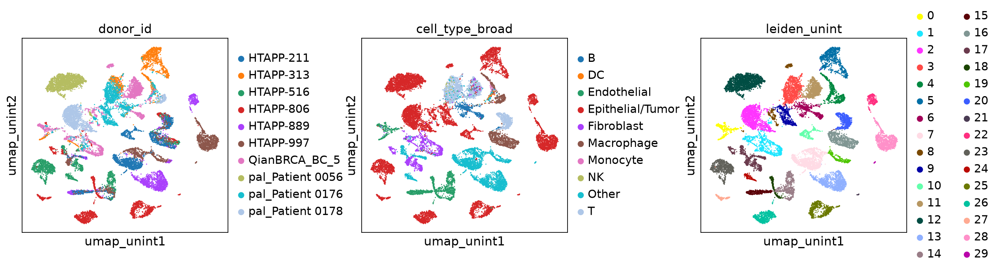

leiden_unint
0     0.58
1     0.59
2     0.98
3     0.63
4     0.36
5     0.99
6     0.53
7     0.70
8     0.67
9     0.94
10    1.00
11    1.00
12    1.00
13    1.00
14    0.59
15    0.55
16    0.47
17    0.41
18    0.97
19    0.64
20    0.40
21    1.00
22    1.00
23    1.00
24    1.00
25    1.00
26    1.00
27    1.00
28    1.00
29    1.00

17 of 30 unintegrated clusters are >80% from one donor


In [25]:
# Cluster WITHOUT integration, then plot by donor, by cell type, and by cluster
try:
    sc.tl.leiden(adata, resolution=0.5, key_added="leiden_unint", flavor="igraph", n_iterations=2, directed=False)
except TypeError:                       # older scanpy without flavor=
    sc.tl.leiden(adata, resolution=0.5, key_added="leiden_unint")
sc.pl.embedding(adata, basis="umap_unint", color=["donor_id", "cell_type_broad", "leiden_unint"],
                wspace=0.5, show=False)
savefig("1_3_umap_unintegrated")

# How donor-driven is each cluster? (share of cells from the single largest donor)
dom_share = pd.crosstab(adata.obs["leiden_unint"], adata.obs["donor_id"], normalize="index").max(axis=1)
print(dom_share.round(2).to_string())
n_donor_driven = int((dom_share > 0.8).sum())
print(f"\n{n_donor_driven} of {len(dom_share)} unintegrated clusters are >80% from one donor")
RESULTS["single_cell"]["unintegrated_clusters"] = int(len(dom_share))
RESULTS["single_cell"]["donor_driven_clusters_gt80pct"] = n_donor_driven

**interpretation:** In one or two sentences, what do these two plots show? Is the data organized by donor or by biology?

**Answer:** Before integration, the cells group mostly by donor rather than by cell type. 17 of the 30 Leiden clusters came almost entirely (over 80%) from a single donor, and 13 of them were made up of just one donor. Comparing the donor and cell-type plots shows that most of these single-donor islands are epithelial/tumor cells, while immune and stromal cells like T cells, macrophages, endothelial cells and fibroblasts are more likely to be shared across patients. Some of this separation is real biology, since each patient's tumor has its own genetic changes and expression program, so malignant cells are expected to stay patient-specific. Part of it is also technical, because the 10 donors come from three different studies (HTAPP, Qian and Pal), each with its own protocol and sequencing setup. Integration should therefore mix the shared immune and stromal cell types across donors, but without forcing genuinely different tumors together.

## 1.4 · Integrate with scVI  *(provided, GPU step)*

In [27]:
import scvi
scvi.settings.seed = 0      # reproducible scVI training for Restart & Run All

[rank: 0] Seed set to 0


In [28]:
import scvi
scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="donor_id")
vae = scvi.model.SCVI(adata, n_latent=30)
vae.train(max_epochs=60, accelerator="cpu")   # P100 GPU (sm_60) unsupported by PyTorch 2.8 -> CPU
adata.obsm["X_scVI"] = vae.get_latent_representation()
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_scVI")
sc.tl.umap(adata)
adata.obsm["X_umap_scvi"] = adata.obsm["X_umap"].copy()
print("scVI done")

/tmp/dineshkumar.de-m8/lib/python3.12/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /shared/EL9/explorer/anaconda3/2024.06/lib/python3.1 ...
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/tmp/dineshkumar.de-m8/lib/python3.12/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /shared/EL9/explorer/anaconda3/2024.06/lib/python3.1 ...
/tmp/dineshkuma

Training:   0%|          | 0/60 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=60` reached.


scVI done


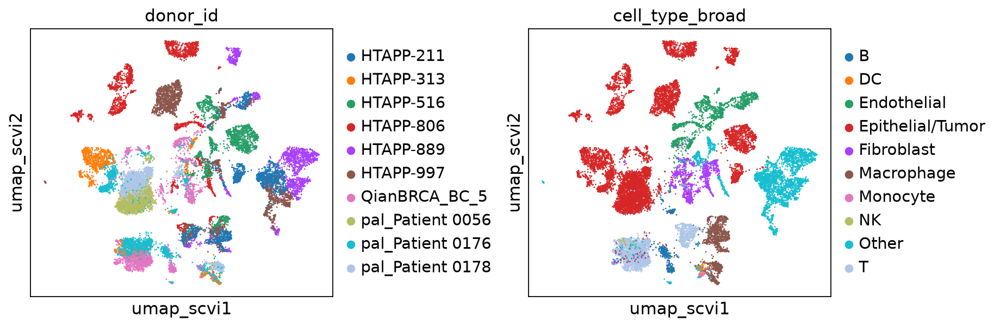

In [29]:
sc.pl.embedding(adata, basis="umap_scvi", color=["donor_id", "cell_type_broad"], wspace=0.5, show=False)
savefig("1_4_umap_scvi")

## 1.5 · Harmony, a fair baseline  *(provided)*

In [30]:
import harmonypy
ho = harmonypy.run_harmony(adata.obsm["X_pca"].astype(np.float64), adata.obs, "donor_id")
Z = np.asarray(ho.Z_corr)
adata.obsm["X_pca_harmony"] = Z if Z.shape[0] == adata.n_obs else Z.T
print("Harmony done")

2026-11-20 01:47:09,256 - harmonypy - INFO - Running Harmony
2026-11-20 01:47:09,256 - harmonypy - INFO -   Parameters:
2026-11-20 01:47:09,257 - harmonypy - INFO -     max_iter_harmony: 10
2026-11-20 01:47:09,257 - harmonypy - INFO -     max_iter_kmeans: 4
2026-11-20 01:47:09,257 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-11-20 01:47:09,258 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-11-20 01:47:09,258 - harmonypy - INFO -     nclust: 100
2026-11-20 01:47:09,259 - harmonypy - INFO -     block_size: 0.05
2026-11-20 01:47:09,259 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-11-20 01:47:09,260 - harmonypy - INFO -     theta: [2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
2026-11-20 01:47:09,260 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-11-20 01:47:09,261 - harmonypy - INFO -     verbose: True
2026-11-20 01:47:09,261 - harmonypy - INFO -     random_state: 0
2026-11-20 01:47:09,262 - harmonypy - INFO -   Data: 50 PCs × 18388 cells
2026-11-20 01:47:09,262 - 

Harmony done


### 1.5b · Harmony UMAP (added so both methods are plotted, per the rubric)

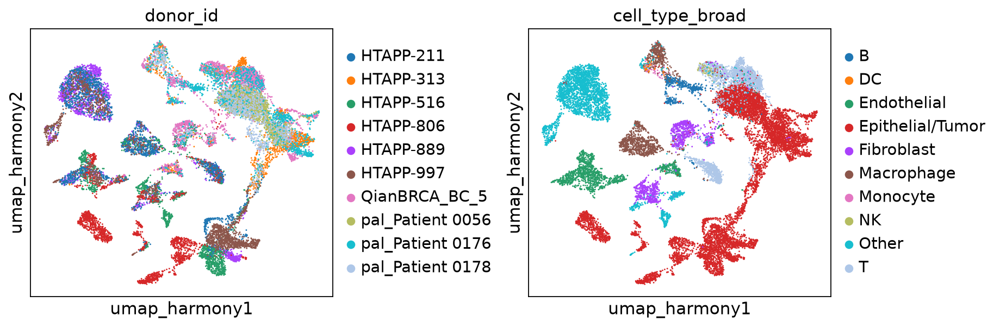

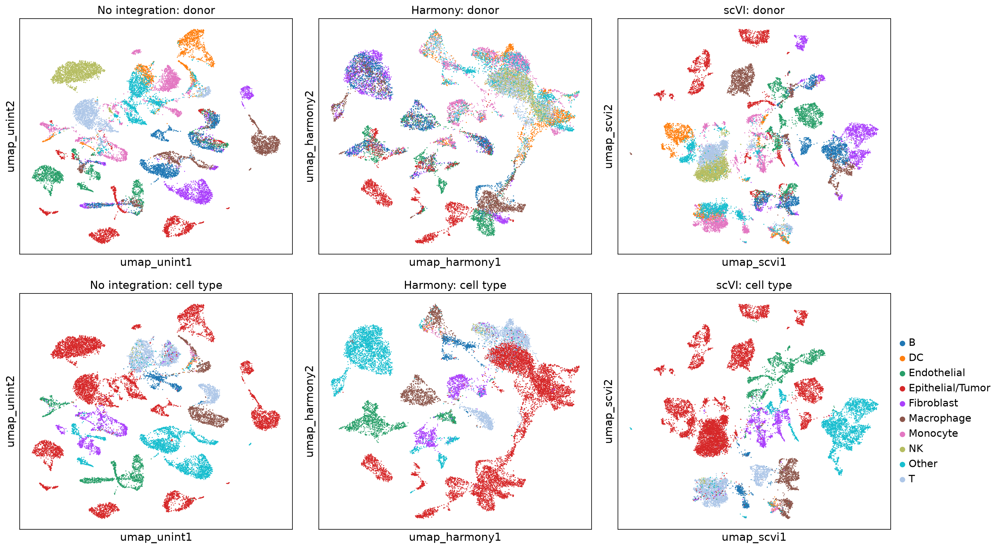

In [31]:
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca_harmony")
sc.tl.umap(adata)
adata.obsm["X_umap_harmony"] = adata.obsm["X_umap"].copy()
sc.pl.embedding(adata, basis="umap_harmony", color=["donor_id", "cell_type_broad"], wspace=0.5, show=False)
savefig("1_5_umap_harmony")

# Side-by-side comparison figure for the report
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for j, (name, basis) in enumerate([("No integration", "umap_unint"), ("Harmony", "umap_harmony"), ("scVI", "umap_scvi")]):
    sc.pl.embedding(adata, basis=basis, color="donor_id", ax=axes[0, j], show=False, title=f"{name}: donor", legend_loc="none")
    sc.pl.embedding(adata, basis=basis, color="cell_type_broad", ax=axes[1, j], show=False, title=f"{name}: cell type",
                    legend_loc=("right margin" if j == 2 else "none"))
plt.tight_layout()
savefig("1_5_integration_comparison")

## 1.6 · Judge the fix
**TODO:** compute how well each method (no integration, Harmony, scVI) mixes donors and preserves cell types, then decide which you would use.

,batch_sil (donor),bio_sil (cell type),batch_mixing = 1-|sil|,bio_conservation = (sil+1)/2,overall (0.4*batch + 0.6*bio)
method,,,,,
No integration,0.128,-0.022,0.872,0.489,0.642
Harmony,-0.088,-0.009,0.912,0.495,0.662
scVI,-0.032,0.033,0.968,0.516,0.697


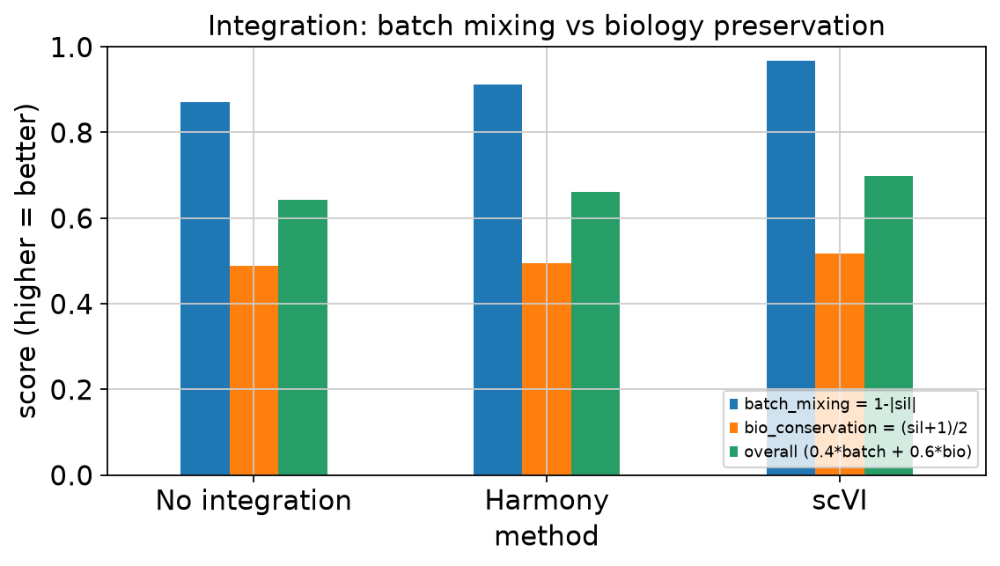

Highest overall score: scVI


In [32]:
from sklearn.metrics import silhouette_score
idx = rng.choice(adata.n_obs, size=min(5000, adata.n_obs), replace=False)
reps = {"No integration": "X_pca", "Harmony": "X_pca_harmony", "scVI": "X_scVI"}
rows = []
for name, key in reps.items():
    emb = adata.obsm[key][idx][:, :30]          # same dimensionality (30) for a fair comparison
    b = silhouette_score(emb, adata.obs["donor_id"].values[idx])
    c = silhouette_score(emb, adata.obs["cell_type_broad"].values[idx])
    rows.append({"method": name, "batch_sil (donor)": b, "bio_sil (cell type)": c,
                 "batch_mixing = 1-|sil|": 1 - abs(b), "bio_conservation = (sil+1)/2": (c + 1) / 2})
scores = pd.DataFrame(rows).set_index("method")
# scIB-style overall score (Luecken et al. 2022): 40% batch removal, 60% biology conservation
scores["overall (0.4*batch + 0.6*bio)"] = 0.4 * scores["batch_mixing = 1-|sil|"] + 0.6 * scores["bio_conservation = (sil+1)/2"]
display(scores.round(3))
scores.round(4).to_csv("figures/integration_scores.csv")

ax = scores[["batch_mixing = 1-|sil|", "bio_conservation = (sil+1)/2", "overall (0.4*batch + 0.6*bio)"]].plot.bar(figsize=(8, 4), rot=0)
ax.set_ylabel("score (higher = better)"); ax.set_ylim(0, 1); ax.set_title("Integration: batch mixing vs biology preservation")
ax.legend(loc="lower right", fontsize=8)
savefig("1_6_integration_scores")

best = scores["overall (0.4*batch + 0.6*bio)"].idxmax()
print("Highest overall score:", best)
RESULTS["single_cell"]["integration_scores"] = scores.round(3).to_dict(orient="index")
RESULTS["single_cell"]["best_overall"] = best

**interpretation:** Which method would you use, and why? Does the expensive deep-learning method clearly beat the simple one?

**Answer:** Based on the scores, I would choose **scVI**, although its advantage over Harmony is fairly small. Batch mixing increased from 0.872 with no integration to 0.912 with Harmony and 0.968 with scVI, and scVI's donor silhouette (−0.032) was the closest to zero, which is what good mixing should look like. Cell-type conservation also improved slightly, from 0.489 to 0.495 with Harmony and 0.516 with scVI. scVI was the only method with a positive cell-type silhouette (0.033), so it mixed donors best while keeping cell types somewhat separated. Its overall score was the highest (0.697, vs 0.662 for Harmony and 0.642 for no integration).

Still, the deep-learning method did not clearly beat the simpler one, since the overall difference between scVI and Harmony was only about 0.035. scVI was also trained for just 60 epochs on CPU, because the assigned P100 GPU was not supported by our PyTorch version, so it may be slightly under-trained. For a broad cell-type question, Harmony would be a reasonable, much cheaper choice.

Some caveats: the cell-type silhouettes are near zero for all three methods, so these broad labels don't form very tight clusters and silhouette is only a rough measure here. Higher donor mixing is also not automatically better in a tumor dataset. If malignant cells from different patients get merged together, that could be over-correction that hides real differences between tumors. Finally, while checking the markers, I found that the starter's keyword-based grouping had placed 8,526 "malignant cell" labels into the T-cell group (because "malignant cell" contains the text "t cell"). I corrected this before computing these scores.

## 1.7 · Annotate and confirm with markers
The broad cell types are already assigned. **TODO:** plot the labeled map and a few canonical markers to confirm it.

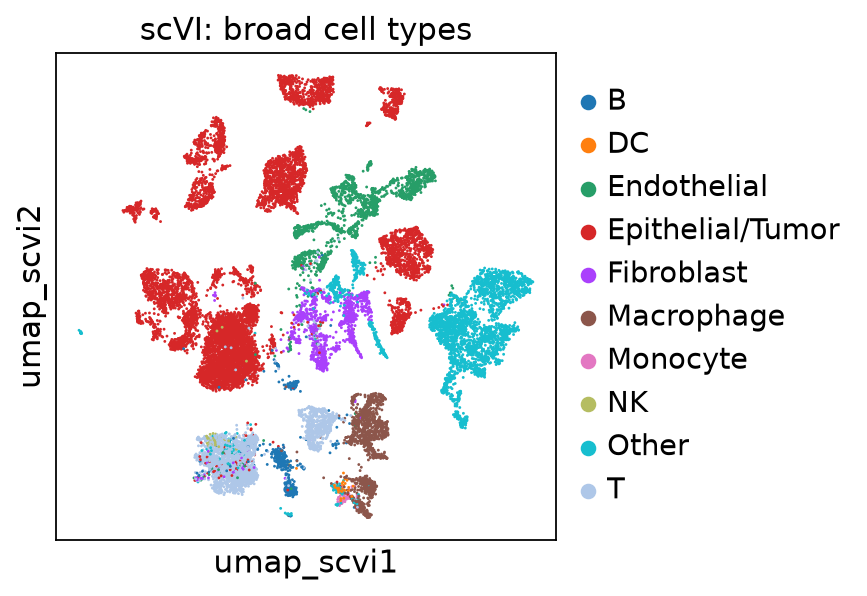

markers plotted: ['CD3D', 'MS4A1', 'NKG7', 'CD14', 'CD68', 'EPCAM', 'KRT18', 'PECAM1', 'COL1A1']


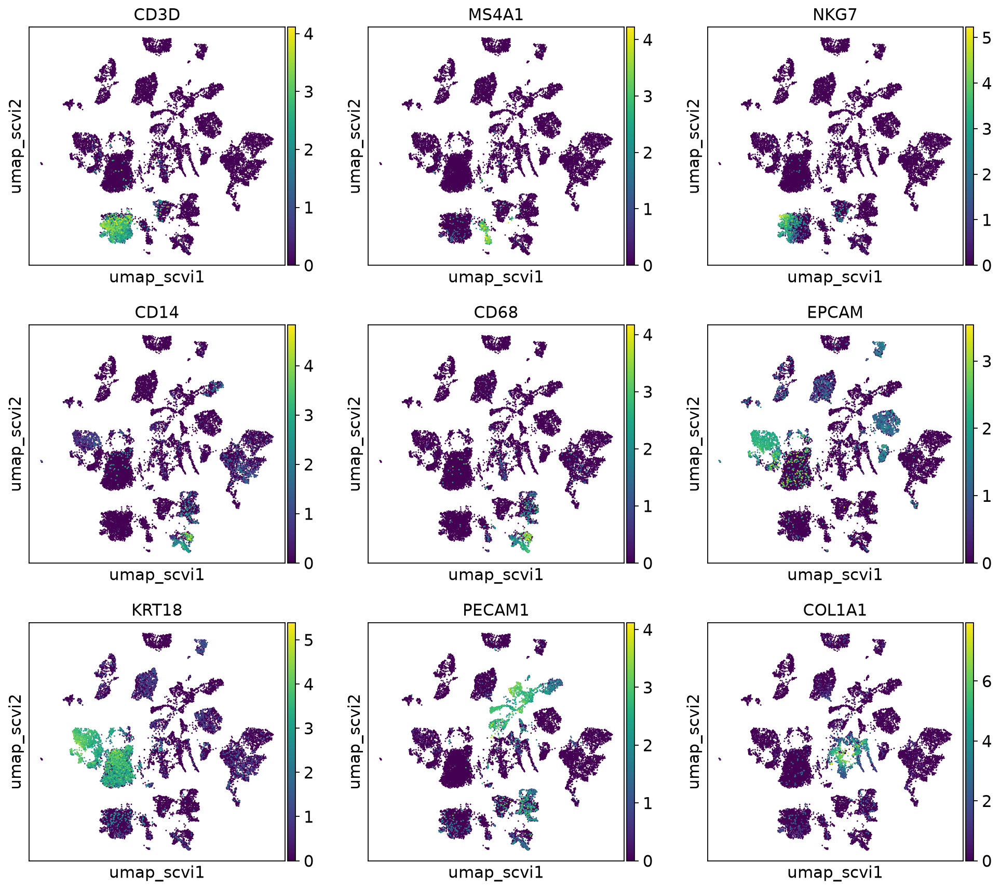

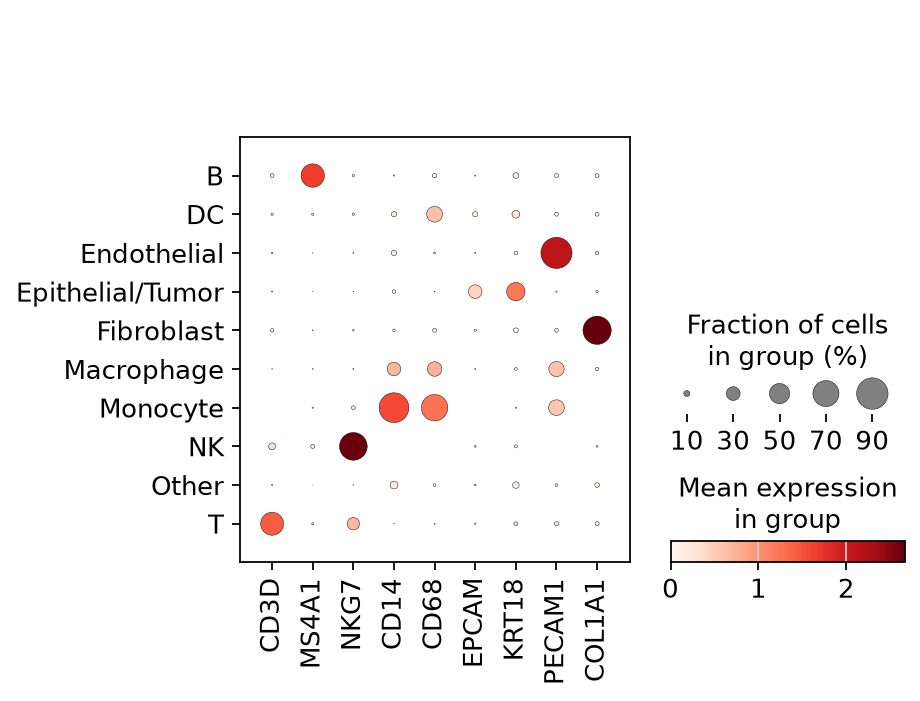

In [33]:
sc.pl.embedding(adata, basis="umap_scvi", color="cell_type_broad", show=False, title="scVI: broad cell types")
savefig("1_7_celltypes_scvi")

markers = [g for g in ["CD3D", "MS4A1", "NKG7", "CD14", "CD68", "EPCAM", "KRT18", "PECAM1", "COL1A1"]
           if g in adata.raw.var_names]
print("markers plotted:", markers)
sc.pl.embedding(adata, basis="umap_scvi", color=markers, use_raw=True, ncols=3, show=False)
savefig("1_7_markers_umap")
sc.pl.dotplot(adata, markers, groupby="cell_type_broad", use_raw=True, show=False)
savefig("1_7_markers_dotplot")

In [34]:
print(adata.obs.loc[adata.obs["cell_type_broad"] == "T", "cell_type"].value_counts().head(12))

cell_type
T cell                                                                      1688
naive T cell                                                                 174
effector memory CD8-positive, alpha-beta T cell                              150
mature NK T cell                                                              72
CD8-positive, alpha-beta regulatory T cell                                    68
effector memory CD4-positive, alpha-beta T cell                               67
CD4-positive, CD25-positive, CCR4-positive, alpha-beta regulatory T cell      67
exhausted T cell                                                              17
cycling T cell                                                                10
capillary endothelial cell                                                     0
blood vessel smooth muscle cell                                                0
blood vessel endothelial cell                                                  0
Name: count, dtype

**Marker check:** After fixing the label mapping, the broad cell types are well supported by canonical markers. CD3D is now clearly specific to T cells, MS4A1 to B cells, NKG7 to NK cells, PECAM1 to endothelial cells and COL1A1 to fibroblasts, each with strong, group-specific expression in the dot plot. CD14 and CD68 mark the monocytes strongly and the macrophages more weakly, and the epithelial/tumor group expresses KRT18 and EPCAM. Before the fix, CD3D was barely detected in the "T" group while EPCAM and KRT18 were high there. That mismatch is what revealed the mapping error, which had placed malignant, myofibroblast and mast cells into the T-cell category because their names contain "t cell."

## 1.8 · Locate your target in the cell types
**TODO:** choose your target gene, plot it, and identify which cell type(s) express it.

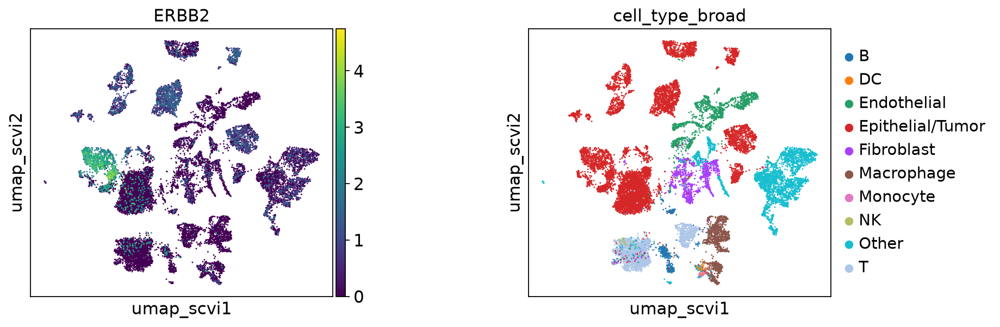

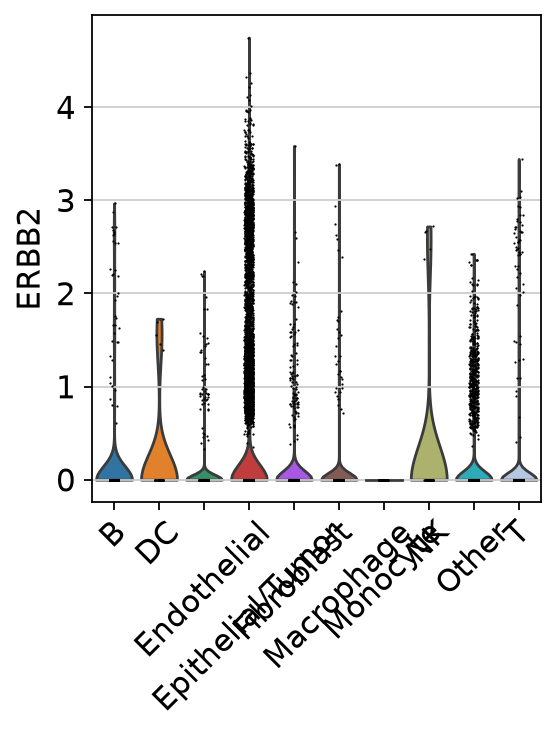

,n_cells,mean_log_expr,pct_expressing
cell_type,,,
Epithelial/Tumor,8678,0.63,36.36
NK,50,0.26,10.00
DC,36,0.22,13.89
Other,2993,0.19,16.97
B,529,0.13,7.18
Fibroblast,1096,0.11,9.58
T,2313,0.06,2.51
Macrophage,1189,0.05,3.03
Endothelial,1431,0.04,3.84


In [35]:
TARGET = "ERBB2"   
assert TARGET in adata.raw.var_names, f"{TARGET} not found in the single-cell genes"

sc.pl.embedding(adata, basis="umap_scvi", color=[TARGET, "cell_type_broad"], use_raw=True, wspace=0.5, show=False)
savefig("1_8_target_umap")
sc.pl.violin(adata, TARGET, groupby="cell_type_broad", use_raw=True, rotation=45, show=False)
savefig("1_8_target_violin")

x = adata.raw[:, TARGET].X
x = x.toarray().ravel() if hasattr(x, "toarray") else np.asarray(x).ravel()
tgt = (pd.DataFrame({"cell_type": adata.obs["cell_type_broad"].values, "expr": x})
       .groupby("cell_type", observed=True)["expr"]
       .agg(n_cells="size", mean_log_expr="mean", pct_expressing=lambda v: 100 * (v > 0).mean())
       .sort_values("mean_log_expr", ascending=False))
display(tgt.round(2))
tgt.round(3).to_csv("figures/target_by_celltype.csv")
RESULTS["target"] = TARGET
RESULTS["single_cell"]["target_by_celltype"] = tgt.round(3).to_dict(orient="index")

### 1.8b · ERBB2 by donor (tumor cells only)
Added analysis: splits ERBB2 expression in epithelial/tumor cells by donor to check whether the pooled percentage hides patient-to-patient differences.

In [36]:
epi = adata[adata.obs["cell_type_broad"] == "Epithelial/Tumor"]
e = epi.raw[:, TARGET].X
e = e.toarray().ravel() if hasattr(e, "toarray") else np.asarray(e).ravel()
display(pd.DataFrame({"donor": epi.obs["donor_id"].values, "expr": e})
        .groupby("donor", observed=True)["expr"]
        .agg(n="size", mean="mean", pct_expr=lambda v: 100*(v > 0).mean())
        .round(2).sort_values("mean", ascending=False))

,n,mean,pct_expr
donor,,,
HTAPP-313,776,2.42,92.91
pal_Patient 0176,563,1.86,66.43
HTAPP-997,1021,0.85,73.36
HTAPP-889,248,0.84,68.15
HTAPP-516,758,0.52,50.79
QianBRCA_BC_5,271,0.45,38.01
HTAPP-806,1421,0.42,33.64
HTAPP-211,241,0.21,17.84
pal_Patient 0056,1963,0.13,4.84


**interpretation:** Which cell type(s) express your target? 

**Answer:** ERBB2 (HER2) is expressed mainly in the **epithelial/tumor** cells, with a mean log-expression of 0.63 and 36% of the 8,678 tumor cells expressing it. Other cell types barely express it: T cells (2.5%), macrophages (3.0%) and endothelial cells (3.8%). The slightly higher values in NK cells and DCs (10–14%) come from very small groups of only 50 and 36 cells, so they aren't reliable. This matches HER2's biology as a receptor on breast cancer epithelial cells.

The pooled 36% hides large differences between patients. When I split the tumor cells by donor, HTAPP-313 (mean 2.42, 93% of tumor cells expressing) and pal_Patient 0176 (1.86, 66%) were clearly ERBB2-high, five donors were intermediate (0.42–0.85, 34–73%), and three were very low, including pal_Patient 0056 (0.13, 5%) and pal_Patient 0178 (0.07, 3%). Those two low donors also contribute the largest numbers of tumor cells, which drags the overall percentage down. This pattern is consistent with a mix of likely HER2-high and HER2-low or HER2-negative tumors in the cohort, although clinical HER2 status (IHC/FISH) isn't available in this dataset, so I can't confirm it. Clinically, this is the key point: HER2-targeted drugs such as trastuzumab are only expected to work in the high-expressing tumors, and HER2 can also vary between cells within the same tumor. Single-cell dropout means these percentages are likely underestimates.

## 2.1 · Load the provided Visium section  *(provided)*
A real 10x human breast-cancer Visium section. Downloads once on the first run.

In [37]:
spatial = sc.datasets.visium_sge(sample_id="V1_Breast_Cancer_Block_A_Section_1")
spatial.var_names_make_unique()
print(spatial)
print("spots x genes:", spatial.shape)

  0%|          | 0.00/9.50M [00:00<?, ?B/s]

  0%|          | 0.00/26.9M [00:00<?, ?B/s]

/tmp/dineshkumar.de-m8/lib/python3.12/site-packages/scanpy/readwrite.py:249: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


AnnData object with n_obs × n_vars = 3798 × 36601
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
    layers: None (.X)
spots x genes: (3798, 36601)


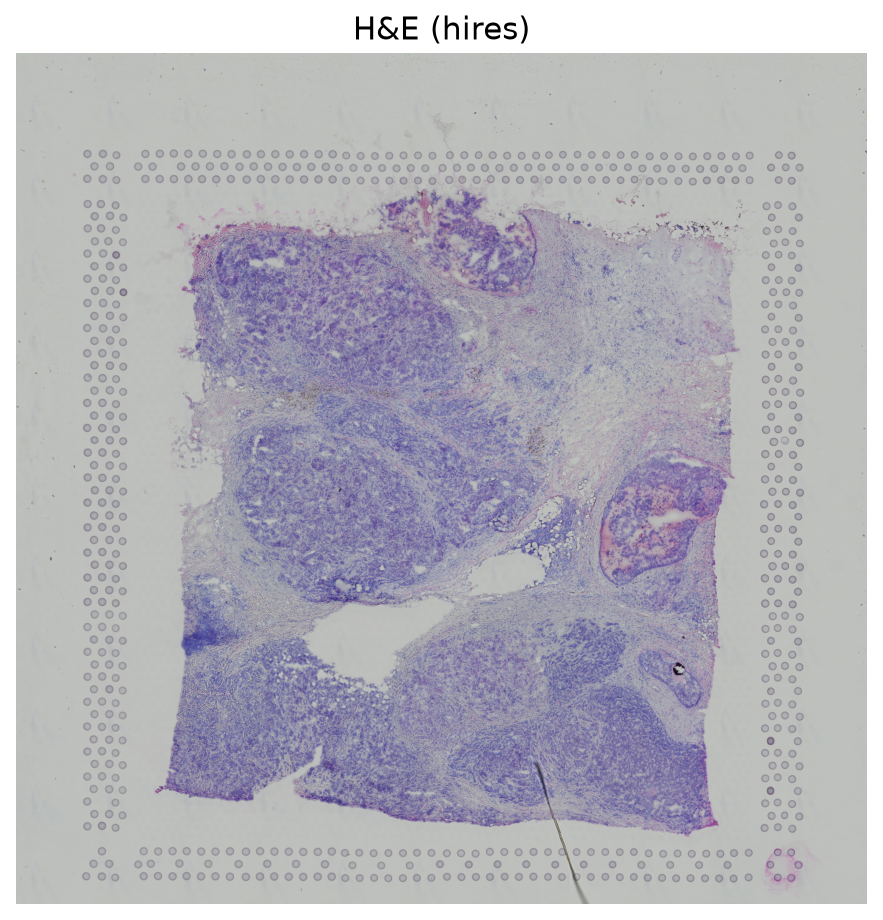

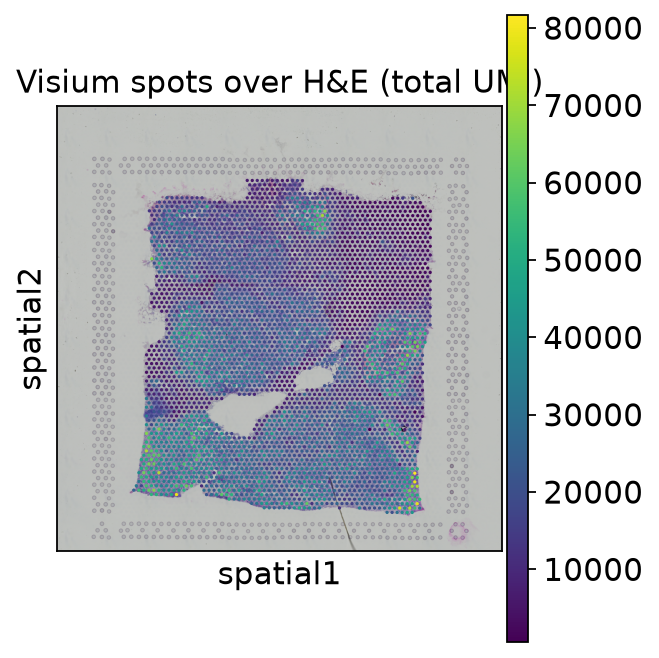

In [38]:
# Spots over the H&E image
lib = list(spatial.uns["spatial"].keys())[0]
img = spatial.uns["spatial"][lib]["images"]["hires"]
plt.figure(figsize=(7, 7)); plt.imshow(img); plt.axis("off"); plt.title("H&E (hires)")
savefig("2_1_he_image")

spatial.obs["total_UMI"] = np.asarray(spatial.X.sum(axis=1)).ravel()
sq.pl.spatial_scatter(spatial, color="total_UMI", title="Visium spots over H&E (total UMI)")
savefig("2_1_spots_on_he")
RESULTS["spatial"] = {"spots_loaded": int(spatial.n_obs), "genes": int(spatial.n_vars)}

## 2.2 · Pipeline and clustering  *(provided)*

In [39]:
spatial.var["mt"] = spatial.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(spatial, qc_vars=["mt"], inplace=True)
sc.pp.filter_cells(spatial, min_counts=500)
spatial.layers["counts"] = spatial.X.copy()
sc.pp.normalize_total(spatial, target_sum=1e4)
sc.pp.log1p(spatial)
spatial.raw = spatial
sc.pp.highly_variable_genes(spatial, n_top_genes=2000)
sc.pp.pca(spatial)
sc.pp.neighbors(spatial)
sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")
print("spatial domains found:", spatial.obs["cluster"].nunique())

spatial domains found: 9


## 2.3 · Spatial domains on the tissue
**TODO:** draw the clusters back onto the tissue and relate them to tumor, stroma, and immune regions.

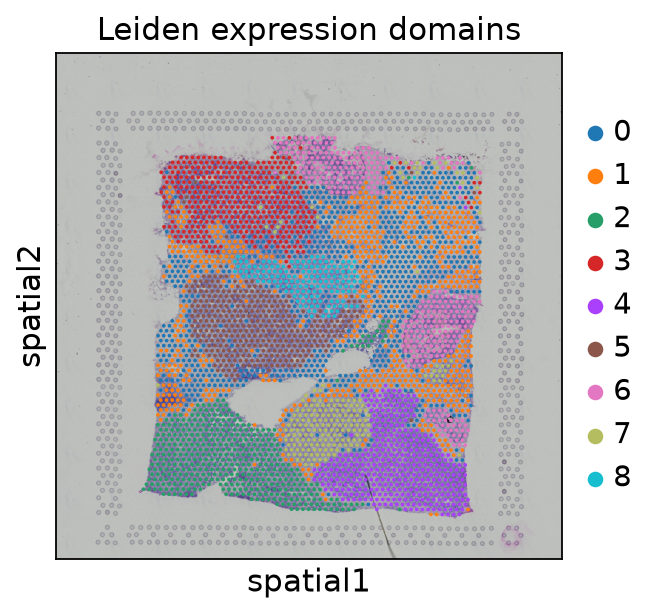

,0,1,2,3,4,5,6,7,8
0,IGKC,C3,CXCL14,COX6C,CRISP3,CPB1,MGP,S100G,LINC00645
1,IGHG3,TIMP1,CCND1,SLC39A6,SLITRK6,IL6ST,SERPINA3,IFI6,MUC5B
2,IGHG4,VIM,TCEAL4,WFDC2,H3F3A,LINC02224,DSP,HEBP1,PVALB
3,MALAT1,DCN,AGR2,MT-ND1,C6orf141,COX6C,S100G,AC087379.2,EXOC2
4,IGHG1,COL6A2,GFRA1,SNCG,IGFBP5,CFB,TFF3,KRT37,SLC30A8
5,IGLC2,SFRP2,GNG5,MT-CO1,S100A13,HLA-B,TFF1,IFT122,TMEM150C
6,IGLC1,BGN,TTLL12,FASN,PSMA6,HLA-C,ACADSB,FAM234B,IGFBP2
7,C3,LUM,MORF4L2,RAB11FIP1,VTCN1,FCGR3B,S100A6,IFI27,COLEC12


signature genes used: {'Tumor': ['EPCAM', 'KRT8', 'KRT18', 'KRT19', 'CDH1', 'CLDN4'], 'Stroma': ['COL1A1', 'COL1A2', 'COL3A1', 'DCN', 'LUM', 'SPARC', 'FN1'], 'Immune': ['PTPRC', 'CD3D', 'CD3E', 'MS4A1', 'CD74', 'HLA-DRA', 'IGKC', 'CD68', 'LYZ']}


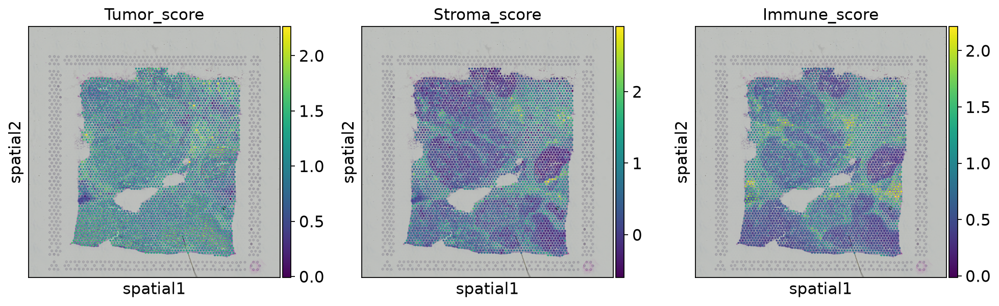

,Tumor_score,Stroma_score,Immune_score,domain
cluster,,,,
0,1.246,0.759,1.104,Tumor
1,0.932,1.253,1.352,Immune
2,1.386,0.690,0.604,Tumor
3,1.231,0.225,0.811,Tumor
4,1.446,0.385,0.563,Tumor
5,1.289,0.195,0.925,Tumor
6,1.295,0.059,0.570,Tumor
7,1.190,0.519,0.997,Tumor
8,1.407,0.336,0.709,Tumor


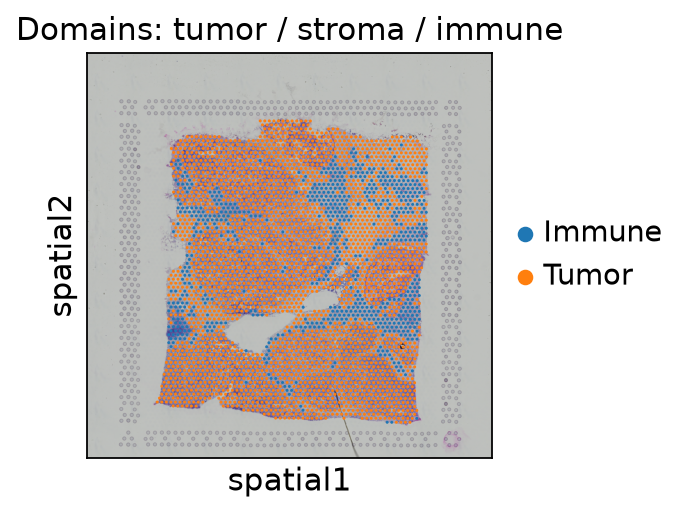

domain
Tumor     3103
Immune     695


In [40]:
sq.pl.spatial_scatter(spatial, color="cluster", title="Leiden expression domains")
savefig("2_3_clusters_on_tissue")

# Top marker genes per domain
sc.tl.rank_genes_groups(spatial, "cluster", method="wilcoxon", use_raw=True)
top_markers = pd.DataFrame(spatial.uns["rank_genes_groups"]["names"]).head(8)
display(top_markers)
top_markers.to_csv("figures/spatial_cluster_markers.csv", index=False)

# Signature scores to call tumor / stroma / immune (TARGET excluded so the domain call is not circular)
sigs = {"Tumor":  ["EPCAM", "KRT8", "KRT18", "KRT19", "CDH1", "CLDN4"],
        "Stroma": ["COL1A1", "COL1A2", "COL3A1", "DCN", "LUM", "SPARC", "FN1"],
        "Immune": ["PTPRC", "CD3D", "CD3E", "MS4A1", "CD74", "HLA-DRA", "IGKC", "CD68", "LYZ"]}
sigs = {k: [g for g in v if g in spatial.raw.var_names and g != TARGET] for k, v in sigs.items()}
print("signature genes used:", sigs)
for k, v in sigs.items():
    sc.tl.score_genes(spatial, v, score_name=f"{k}_score", use_raw=True, random_state=0)
sq.pl.spatial_scatter(spatial, color=[f"{k}_score" for k in sigs], ncols=3)
savefig("2_3_signature_scores")

cl = spatial.obs.groupby("cluster", observed=True)[[f"{k}_score" for k in sigs]].mean()b
cl["domain"] = cl.idxmax(axis=1).str.replace("_score", "")
# Manual override if a cluster is clearly mislabelled versus the H&E, e.g.:  cl.loc["5", "domain"] = "Immune"
display(cl.round(3))
spatial.obs["domain"] = spatial.obs["cluster"].astype(str).map(cl["domain"].rename(index=str)).astype("category")
sq.pl.spatial_scatter(spatial, color="domain", title="Domains: tumor / stroma / immune")
savefig("2_3_domains_on_tissue")

print(spatial.obs["domain"].value_counts().to_string())
RESULTS["spatial"]["n_clusters"] = int(spatial.obs["cluster"].nunique())
RESULTS["spatial"]["cluster_to_domain"] = cl["domain"].to_dict()
RESULTS["spatial"]["spots_per_domain"] = spatial.obs["domain"].value_counts().to_dict()

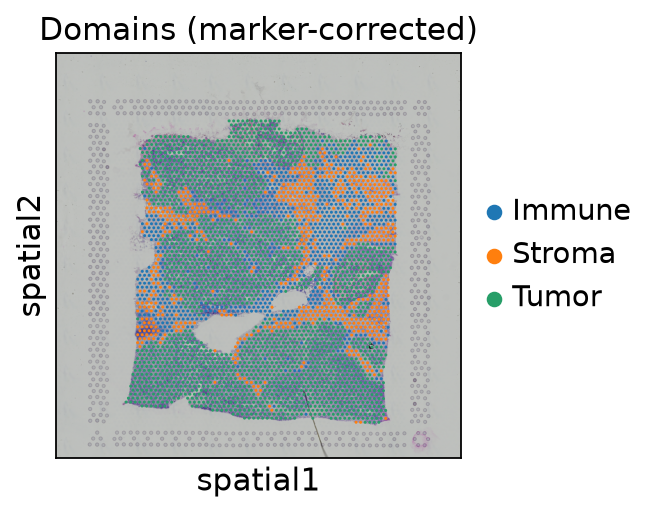

domain
Tumor     2376
Immune     727
Stroma     695


In [41]:
# Manual domain correction from marker genes: raw signature scores are on different
# scales (keratins dominate), so argmax called almost everything "Tumor".
# Cluster 0 = immunoglobulin genes (plasma/B cells); cluster 1 = DCN/LUM/BGN/COL6A2 (stroma).
manual = {"0": "Immune", "1": "Stroma"}
spatial.obs["domain"] = (spatial.obs["cluster"].astype(str)
                         .map(lambda c: manual.get(c, "Tumor")).astype("category"))
spatial.uns.pop("domain_colors", None)
sq.pl.spatial_scatter(spatial, color="domain", title="Domains (marker-corrected)")
savefig("2_3_domains_corrected")
print(spatial.obs["domain"].value_counts().to_string())
RESULTS["spatial"]["cluster_to_domain"] = {c: manual.get(c, "Tumor") for c in spatial.obs["cluster"].cat.categories.astype(str)}
RESULTS["spatial"]["spots_per_domain"] = spatial.obs["domain"].value_counts().to_dict()

**interpretation:** Do the domains line up with recognizable tissue architecture (tumor nests, stroma, immune areas)?

**Answer:** The Leiden clusters form clear, continuous regions on the tissue rather than scattered noise, even though spot location wasn't used for clustering, so they reflect real tissue architecture. Most of the section is tumor (7 of 9 clusters, 2,376 of 3,798 spots, about 63%), matching the dense epithelial regions on the H&E. The tumor clusters express luminal and estrogen-responsive genes such as TFF1, TFF3, AGR2, CCND1 and SLC39A6, which suggests an ER-positive-like tumor. Cluster 1 is **stroma** (695 spots), with fibroblast and matrix genes (DCN, LUM, BGN, COL6A2), and it forms bands running between the tumor regions. Cluster 0 is an **immune** region (727 spots) dominated by immunoglobulin genes (IGKC, IGHG1/3/4, IGLC1/2), indicating plasma and B cells, mostly in the upper part of the section. My first automatic labeling compared raw signature scores and called almost everything "Tumor," because keratin genes are expressed much more strongly than stromal or immune genes, so I corrected the labels using each cluster's marker genes. Since each 55 µm spot contains several cells, these labels describe the dominant composition of each region rather than pure cell types.

## 2.4 · Spatially variable genes (Moran's I)
The spatial neighbor graph is built for you. **TODO:** compute Moran's I, list the top genes, and plot a few.

In [42]:
sq.gr.spatial_neighbors(spatial)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


,I,pval_norm_fdr_bh
MGP,0.868504,0.0
MALAT1,0.762550,0.0
CRISP3,0.726334,0.0
CPB1,0.711023,0.0
IGHG3,0.703817,0.0
IGLC2,0.700306,0.0
IGKC,0.680696,0.0
ALB,0.667866,0.0
IGHG1,0.635266,0.0
IGHG4,0.631525,0.0


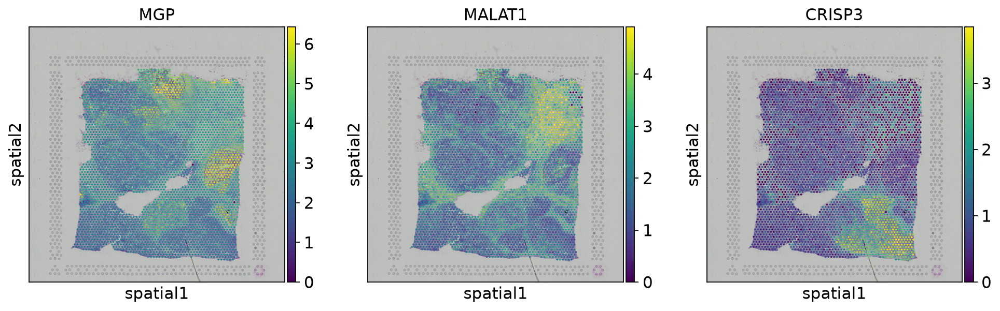

,I,pval_norm,var_norm,pval_norm_fdr_bh
ERBB2,0.236518,0.0,0.000092,0.0


In [43]:
sq.gr.spatial_autocorr(spatial, mode="moran")          # on the 2,000 HVGs, using log-normalized X
moran = spatial.uns["moranI"]
display(moran[["I", "pval_norm_fdr_bh"]].head(10))
moran.head(50).to_csv("figures/moranI_top50.csv")
sq.pl.spatial_scatter(spatial, color=moran.head(3).index.tolist(), ncols=3)
savefig("2_4_top_spatially_variable_genes")

# Moran's I of the target itself (may not be an HVG); copy=True keeps the table above intact
target_moran = sq.gr.spatial_autocorr(spatial, mode="moran", genes=[TARGET], copy=True)
display(target_moran)
RESULTS["spatial"]["top10_moranI"] = moran["I"].head(10).round(3).to_dict()
RESULTS["spatial"]["target_moranI"] = float(target_moran["I"].iloc[0])

**Spatially variable genes:** The top genes by Moran's I were MGP (I = 0.87), MALAT1 (0.76), CRISP3 (0.73), CPB1 (0.71), IGHG3 (0.70), IGLC2 (0.70) and IGKC (0.68), all with FDR < 0.05. They fall into a few clear groups. The immunoglobulin genes (IGHG1/3/4, IGLC2, IGKC) mark the plasma-cell-rich immune region. CRISP3 and CPB1 were top markers of individual tumor clusters (clusters 4 and 5) and are each restricted to one part of the tumor, which suggests different tumor subregions have their own expression programs, so the tumor itself is spatially heterogeneous. MGP is concentrated in specific regions on the right side of the section. MALAT1 is a nuclear long non-coding RNA that often tracks cell density or RNA capture rather than a specific cell type, so its high score is probably partly technical. ALB (albumin) also appears in the top 10, which is unexpected in breast tissue and may reflect serum or ambient RNA rather than local expression. **ERBB2** itself has a Moran's I of 0.24, which is significant but much lower than the top genes. This makes sense: ERBB2 is high across most of the tumor, which covers about two-thirds of the section, so it doesn't form sharp local patches the way markers of small regions do.

## 2.5 · Neighborhood enrichment
**TODO:** compute which domains sit next to each other more than chance, and read off any tumor-immune interface.

nhood_enrichment:   0%|          | 0/1000 [00:00<?, ?perm/s]

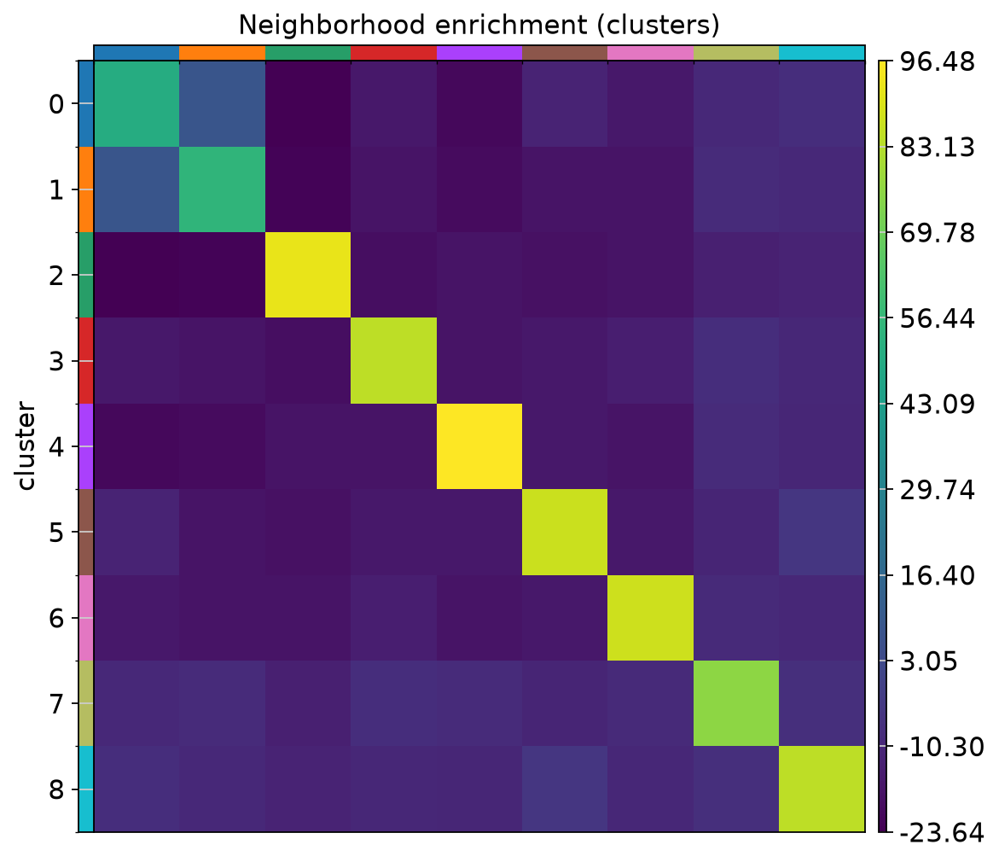

nhood_enrichment:   0%|          | 0/1000 [00:00<?, ?perm/s]

,Immune,Stroma,Tumor
Immune,50.9,8.2,-56.2
Stroma,8.2,54.8,-56.3
Tumor,-56.2,-56.3,69.5


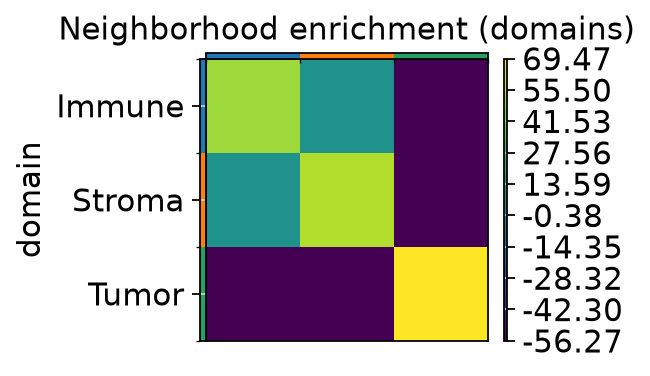

Tumor-Immune z = -56.2 -> depleted (immune-excluded pattern)


In [44]:
sq.gr.nhood_enrichment(spatial, cluster_key="cluster", seed=0)
sq.pl.nhood_enrichment(spatial, cluster_key="cluster", title="Neighborhood enrichment (clusters)")
savefig("2_5_nhood_clusters")

# Same analysis on the 3 labelled domains: easiest to read
sq.gr.nhood_enrichment(spatial, cluster_key="domain", seed=0)
cats = spatial.obs["domain"].cat.categories
z = pd.DataFrame(spatial.uns["domain_nhood_enrichment"]["zscore"], index=cats, columns=cats)
display(z.round(1))
sq.pl.nhood_enrichment(spatial, cluster_key="domain", title="Neighborhood enrichment (domains)")
savefig("2_5_nhood_domains")

if {"Tumor", "Immune"} <= set(cats):
    zt = float(z.loc["Tumor", "Immune"])
    print(f"Tumor-Immune z = {zt:.1f} ->",
          "enriched interface (immune cells contact tumor)" if zt > 2 else
          "depleted (immune-excluded pattern)" if zt < -2 else "no clear enrichment")
    RESULTS["spatial"]["tumor_immune_z"] = round(zt, 2)
RESULTS["spatial"]["domain_nhood_z"] = z.round(2).to_dict()

**interpretation:** Which domains interface more than chance? Is there a tumor-immune boundary?

**Answer:** All three domains are strongly self-enriched (diagonal z = 50.9 for immune, 54.8 for stroma and 69.5 for tumor), as expected for continuous tissue regions. The only positive off-diagonal pair is **immune–stroma** (z = 8.2), meaning immune spots sit next to stroma more often than chance. The same pattern appears at the cluster level, where clusters 0 (immune) and 1 (stroma) are the only pair with clear mutual enrichment. In contrast, **tumor–immune** (z = −56.2) and tumor–stroma (z = −56.3) are both strongly depleted. This suggests an **immune-excluded-like pattern**: the plasma and B cells are found mainly in the stromal compartment around tumor nests rather than infiltrating them. One caveat is that the tumor forms large continuous areas, so most tumor spots are surrounded only by other tumor spots, which pushes both off-diagonal z-scores strongly negative. Immune and tumor regions do still meet at the tumor edges (683 tumor spots border a non-tumor spot), so this is not complete separation. Also, the immune domain here is mainly plasma/B cells, so it doesn't tell us whether T cells infiltrate the tumor.

## 2.6 · Locate your target in the tissue
**TODO:** color the tissue by the same target gene and describe where it sits.

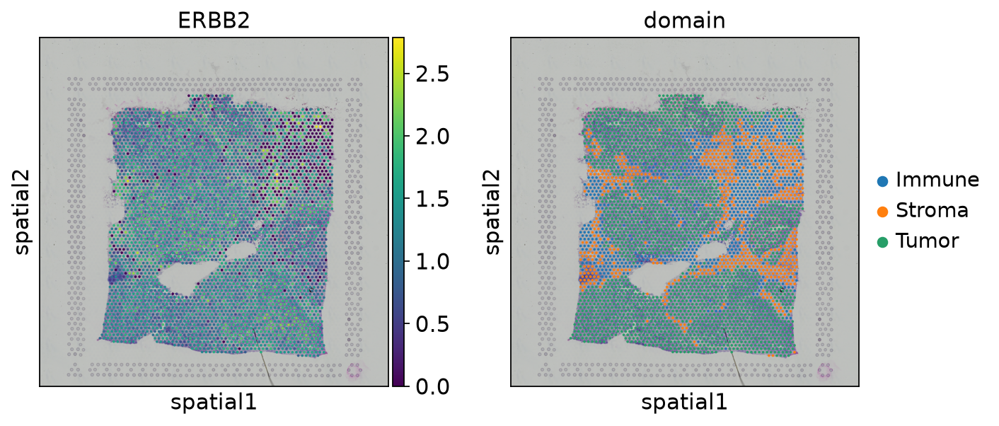

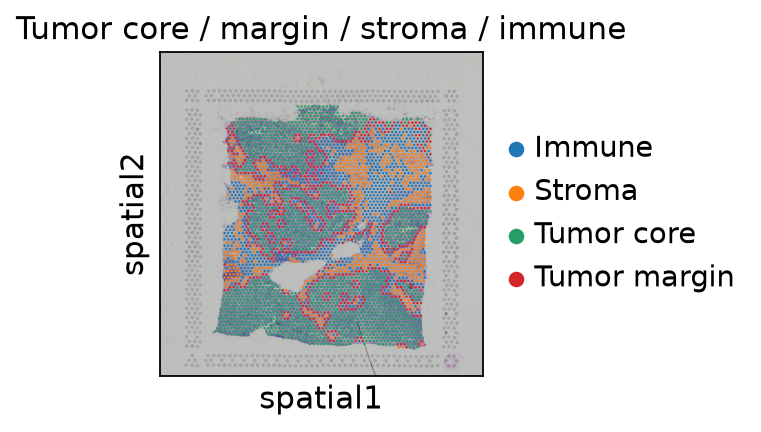

,n_spots,mean_log_expr,pct_positive
region,,,
Tumor core,1693,1.476,98.996
Tumor margin,683,1.438,96.633
Immune,727,1.217,80.330
Stroma,695,0.978,83.453


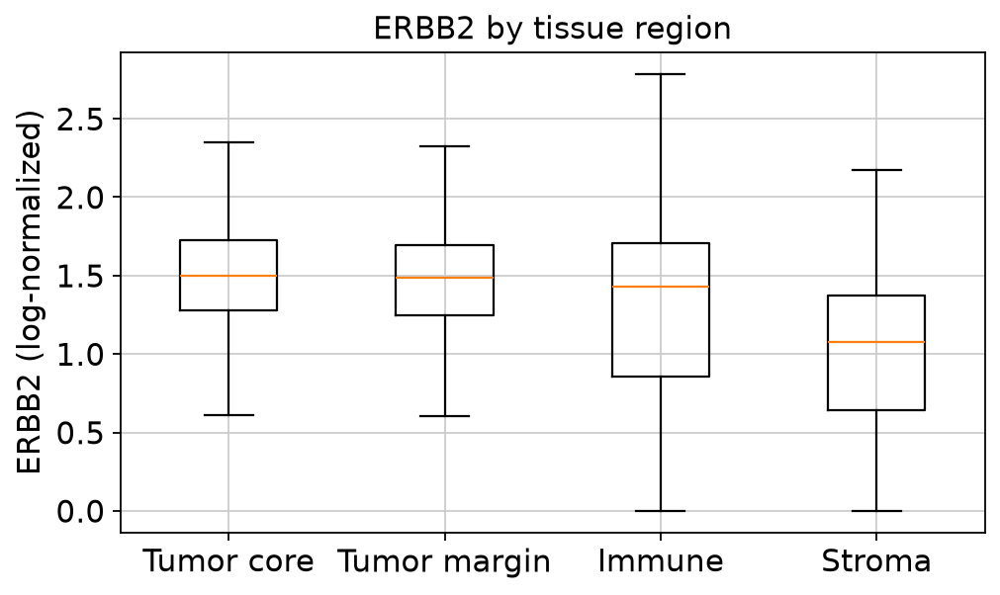

Core vs margin: mean 1.476 vs 1.438; Mann-Whitney U p = 1.22e-01


In [45]:
from scipy.stats import mannwhitneyu
assert TARGET in spatial.raw.var_names, f"{TARGET} not in this Visium panel"
sq.pl.spatial_scatter(spatial, color=[TARGET, "domain"], ncols=2)
savefig("2_6_target_on_tissue")

# Define tumor core vs tumor margin: margin = tumor spots with >=1 non-tumor neighbour on the Visium hex grid
A = spatial.obsp["spatial_connectivities"]
tum = (spatial.obs["domain"].astype(str) == "Tumor").to_numpy()
nontumor_nbrs = np.asarray(A @ (~tum).astype(float)).ravel()
dom = spatial.obs["domain"].astype(str).to_numpy()
spatial.obs["region"] = pd.Categorical(np.where(tum, np.where(nontumor_nbrs > 0, "Tumor margin", "Tumor core"), dom))
sq.pl.spatial_scatter(spatial, color="region", title="Tumor core / margin / stroma / immune")
savefig("2_6_regions")

e = spatial.raw[:, TARGET].X
e = e.toarray().ravel() if hasattr(e, "toarray") else np.asarray(e).ravel()
reg = pd.DataFrame({"region": spatial.obs["region"].values, "expr": e})
reg_tab = (reg.groupby("region", observed=True)["expr"]
           .agg(n_spots="size", mean_log_expr="mean", pct_positive=lambda v: 100 * (v > 0).mean())
           .sort_values("mean_log_expr", ascending=False))
display(reg_tab.round(3)); reg_tab.round(4).to_csv("figures/target_by_region.csv")

fig, ax = plt.subplots(figsize=(7, 4))
order = reg_tab.index.tolist()
ax.boxplot([reg.loc[reg.region == r, "expr"] for r in order], showfliers=False)
ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order)
ax.set_ylabel(f"{TARGET} (log-normalized)"); ax.set_title(f"{TARGET} by tissue region")
savefig("2_6_target_by_region_box")

core = reg.loc[reg.region == "Tumor core", "expr"]; margin = reg.loc[reg.region == "Tumor margin", "expr"]
if len(core) and len(margin):
    stat, p = mannwhitneyu(core, margin, alternative="two-sided")
    print(f"Core vs margin: mean {core.mean():.3f} vs {margin.mean():.3f}; Mann-Whitney U p = {p:.2e}")
    RESULTS["spatial"]["core_vs_margin"] = {"core_mean": round(float(core.mean()), 3),
                                            "margin_mean": round(float(margin.mean()), 3), "p": float(p)}
else:
    print("No core/margin split possible (no Tumor domain called) — read location from the plots instead.")
RESULTS["spatial"]["target_by_region"] = reg_tab.round(3).to_dict(orient="index")

**interpretation:** Where does your target sit: tumor core, invasive margin, or an immune niche?

**Answer:** ERBB2 is expressed **throughout the tumor, at both the core and the margin**, rather than being concentrated at one edge or in an immune niche. Mean expression was 1.48 in tumor core spots (99% positive) and 1.44 at the tumor margin (97% positive), with no significant difference between them (Mann–Whitney p = 0.12). Expression was lower in stroma (0.98) and immune regions (1.22). The fairly high positivity in those regions (80–83%) is most likely because each Visium spot captures several cells, so spots at domain edges often include some tumor cells. This matches Part 1, where ERBB2 was expressed almost entirely by epithelial/tumor cells: those cells make up the tumor domains here. The section's ERBB2 level is high and uniform, closer to the ERBB2-high donors in Part 1 (HTAPP-313 and pal_Patient 0176) than to the low ones, although Visium and single-cell values aren't directly comparable. Clinically, expression reaching the margin means HER2 is accessible to circulating antibodies such as trastuzumab and to immune effector cells. Because it is equally high in the core, how far antibodies penetrate into the tumor (the binding-site barrier) still matters for treatment. "Margin" here is a one-spot (about 100 µm) rim of tumor bordering stroma or immune tissue within this section, not necessarily the tumor's true invasive front.

---
## Results summary (for the README and report)
Collects the key numbers from every section into `figures/results_summary.json`.

In [46]:
def _clean(o):
    if isinstance(o, dict):  return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.integer,)):  return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return o
with open("figures/results_summary.json", "w") as f:
    json.dump(_clean(RESULTS), f, indent=2)
print(json.dumps(_clean(RESULTS), indent=2))
print("\nFigures saved:", sorted(os.listdir("figures")))

{
  "single_cell": {
    "cells_loaded": 20000,
    "donors": 10,
    "assays": {
      "10x 3' v3": 13922,
      "10x 3' v2": 4078,
      "10x 5' v2": 2000,
      "10x 3' v1": 0,
      "10x 3' transcription profiling": 0,
      "10x 5' transcription profiling": 0,
      "10x 5' v1": 0,
      "10x gene expression flex": 0,
      "10x multiome": 0,
      "Asteria scRNA-seq kit": 0,
      "BD Rhapsody Targeted mRNA": 0,
      "BD Rhapsody Whole Transcriptome Analysis": 0,
      "CEL-seq": 0,
      "CEL-seq2": 0,
      "Drop-seq": 0,
      "GEXSCOPE technology": 0,
      "HIVE CLX Single-Cell RNAseq Solution": 0,
      "MARS-seq": 0,
      "Parse Evercode Whole Transcriptome v2": 0,
      "Quartz-seq": 0,
      "SORT-seq": 0,
      "SPLiT-seq": 0,
      "STRT-seq": 0,
      "ScaleBio single cell RNA sequencing": 0,
      "Seq-Well": 0,
      "Seq-Well S3": 0,
      "Smart-seq": 0,
      "Smart-seq v4": 0,
      "Smart-seq2": 0,
      "Smart-seq3": 0,
      "TruDrop": 0,
      "inDrop": 0,

---
# PART 3 · Connect it (your report)

Write a 4–5 page report (separate PDF) that ties the two views together:

- Which cell types express your target (Part 1), and where those cells sit in the tumor (Part 2).
- Your integration choice, justified with the scores.
- The spatial context and why it matters clinically (a target at the invasive margin versus shut inside the core).
- The limitations of each analysis: donor count and label resolution (single-cell); spot resolution, panel, and segmentation (spatial).

Then **Kernel → Restart & Run All**, commit this notebook and your report to your biot6900 repo, and post the repo link on Canvas.